# Levitated optomechanics: from optical forces to LQG stabilisation
### An illustrated, executable tutorial with one numerical example throughout

**Goal.** Understand (1) why light can trap a particle, (2) how the particle moves in a noisy optical potential, (3) the difference between cooling a stable trap and stabilising an unstable one, and (4) how a Kalman filter and LQR form an LQG controller.

**Approach.** We start from Newton's law, use one-dimensional models before extending to a two-dimensional double well, and generate figures from every important equation. No control-systems package is required: just NumPy, SciPy and Matplotlib.

**Source and scope.** Motivated by Mlynář *et al.*, *FPGA-based LQG controller and hardware-in-the-loop simulator implementation for nanomechanical systems* (2026), especially §§2–4 and Fig. 5 (the PDF provided in the conversation). The paper uses an FPGA controller and a second FPGA as a hardware-in-the-loop simulator. **Our examples are illustrative software simulations, not reproductions of its measured traces or parameter settings.** We use classical mechanics and classical stochastic control; we do not claim quantum ground-state cooling.

**Learning path:** Run all cells in order. Figures are produced automatically. Experiment with the clearly marked parameters and exercises near the end.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_continuous_are, solve_discrete_are, expm
from scipy.signal import cont2discrete
from scipy.stats import norm
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.grid': True, 'grid.alpha': .25, 'font.size': 11})
rng = np.random.default_rng(12)
print('Ready: NumPy', np.__version__)

Ready: NumPy 2.4.6


## 1. How can light hold up a particle?

Photons carry momentum. A small dielectric particle polarises in an electric field, and in a **nonuniform** laser beam it experiences a force toward greater intensity (when its polarizability is positive).

In the Rayleigh (small-particle) regime, for a nonabsorbing isotropic particle in vacuum,

$$
\alpha=4\pi\epsilon_0 a^3\frac{\epsilon_r-1}{\epsilon_r+2},\qquad
U(\mathbf r)=-\frac{\alpha}{2\epsilon_0c}I(\mathbf r),\qquad
\mathbf F_{\rm grad}=-\nabla U.
$$

This is a **gradient force**, distinct from the forward-directed **scattering/radiation-pressure force**. A real three-dimensional trap must balance both, as well as gravity and disturbances. We initially study a transverse slice of the beam, where the gradient force is easiest to see.

For a Gaussian intensity profile \(I(x)=I_0 e^{-2x^2/w^2}\), the potential is \(U(x)=-U_0e^{-2x^2/w^2}\).

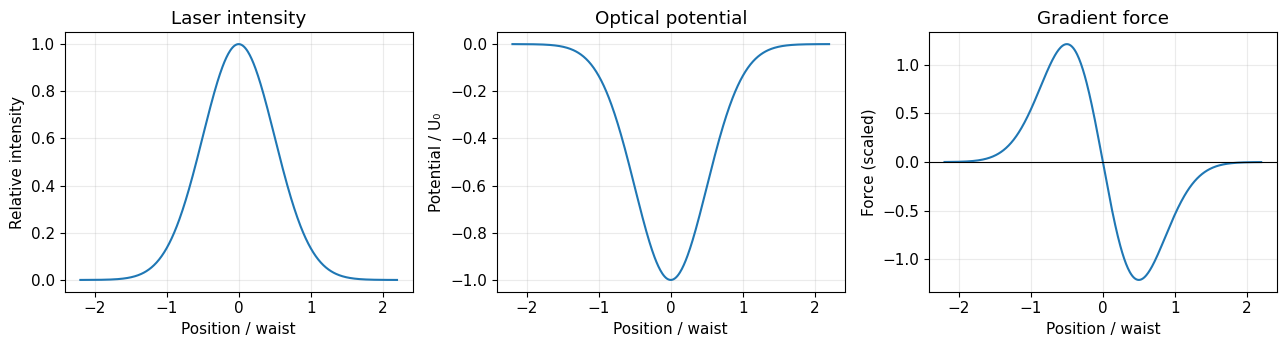

In [2]:
x = np.linspace(-2.2, 2.2, 500) # x / beam waist
I = np.exp(-2*x*x)
U = -I
F = -4*x*np.exp(-2*x*x) # -dU/dx
fig, ax = plt.subplots(1, 3, figsize=(13,3.6))
ax[0].plot(x,I); ax[0].set(title='Laser intensity',xlabel='Position / waist',ylabel='Relative intensity')
ax[1].plot(x,U); ax[1].set(title='Optical potential',xlabel='Position / waist',ylabel='Potential / U₀')
ax[2].plot(x,F); ax[2].axhline(0,color='k',lw=.8); ax[2].set(title='Gradient force',xlabel='Position / waist',ylabel='Force (scaled)')
fig.tight_layout();plt.show()

**Read the graphs:** the particle is attracted toward the intensity maximum at \(x=0\). Close to that minimum, the force is approximately proportional to displacement: a spring! The above one-dimensional model is not by itself a proof of stable 3D levitation.

## 2. The optical trap is approximately a harmonic oscillator

Taylor-expand the potential near \(x=0\):

$$
U(x)\simeq-U_0+\frac12kx^2,\quad k=\frac{4U_0}{w^2},\quad \Omega=\sqrt{k/m}.
$$

Newton's law, including gas damping, external feedback, and a fluctuating force, becomes

$$
m\ddot x+m\Gamma\dot x+m\Omega^2x=u(t)+F_{\rm noise}(t).
$$

The three important effects are **restoring stiffness** \(m\Omega^2\), **damping** \(m\Gamma\), and **random excitation**. The laser typically supplies the restoring force; feedback is optional for a stable trap.

In [ ]:
xx=np.linspace(-1.5,1.5,400)
exact=-np.exp(-2*xx**2)+1
quad=2*xx**2
plt.plot(xx,exact,label='Gaussian trap (offset to zero)')
plt.plot(xx,quad,'--',label='Harmonic approximation')
plt.ylim(-.05,1.3);plt.xlabel('Displacement / waist');plt.ylabel('Potential / U₀');plt.title('The spring model is local');plt.legend();plt.show()

## 3. Stable versus unstable equilibrium

A stable equilibrium sits at the **bottom** of a potential. A particle displaced slightly feels a restoring force. An unstable equilibrium sits at the **top**: a small displacement grows.

$$
\text{Stable: }\ddot x=-\Omega^2x-\Gamma\dot x,\qquad
\text{Unstable: }\ddot x=+\Omega^2x-\Gamma\dot x.
$$

In the paper's saddle-potential demonstration, one direction is locally unstable. This is the key reason feedback is **necessary for confinement**, not merely useful for cooling.

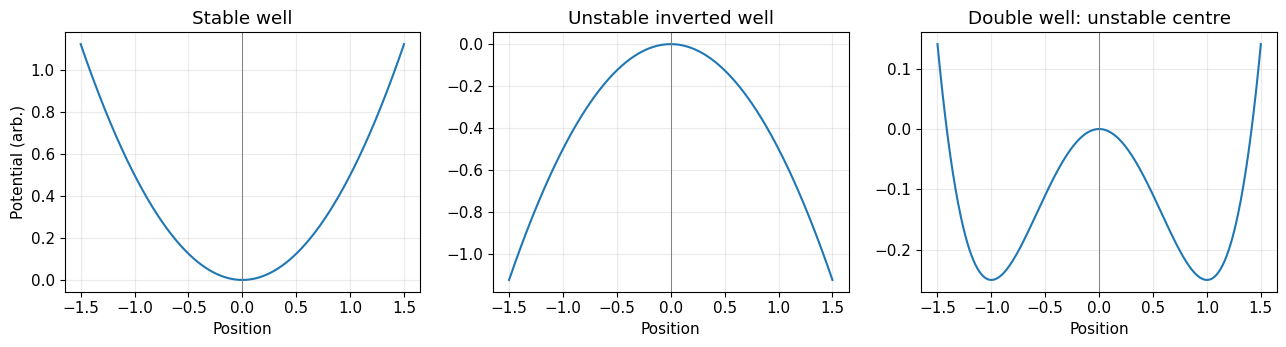

In [4]:
xx=np.linspace(-1.5,1.5,500)
fig,axs=plt.subplots(1,3,figsize=(13,3.6))
axs[0].plot(xx,.5*xx**2);axs[0].set(title='Stable well',ylabel='Potential (arb.)')
axs[1].plot(xx,-.5*xx**2);axs[1].set(title='Unstable inverted well')
axs[2].plot(xx,.25*xx**4-.5*xx**2);axs[2].set(title='Double well: unstable centre')
for a in axs:a.set(xlabel='Position');a.axvline(0,color='gray',lw=.7)
fig.tight_layout();plt.show()

## 4. One numerical particle, two kinds of trap

We now use **dimensionless units** so the plots are readable and the feedback equations are transparent. Time is measured in units of \(1/\Omega_0\), and position in an arbitrary reference displacement. Let the characteristic angular frequency be \(\Omega_0=1\) and damping \(\Gamma=0.12\). This is *not* a fit to the paper's physical apparatus.

Let \(s=+1\) denote stable stiffness and \(s=-1\) inverted stiffness:

$$
\frac{d}{dt}\begin{bmatrix}x\\v\end{bmatrix}=
\underbrace{\begin{bmatrix}0&1\\-s\Omega_0^2&-\Gamma\end{bmatrix}}_A
\begin{bmatrix}x\\v\end{bmatrix}+
\underbrace{\begin{bmatrix}0\\1\end{bmatrix}}_B u.
$$

First, observe the unforced deterministic response from the same initial displacement.

In [ ]:
omega=1.0; gamma=.12
B=np.array([[0.],[1.]])
def plant(s):return np.array([[0.,1.],[-s*omega**2,-gamma]])
t=np.linspace(0,18,800);z0=np.array([.25,0.])
plt.plot(t,[ (expm(plant(1)*tt)@z0)[0] for tt in t],label='Stable trap')
plt.plot(t,[ (expm(plant(-1)*tt)@z0)[0] for tt in t],label='Inverted trap')
plt.ylim(-2,8);plt.xlabel('Time (normalised)');plt.ylabel('Displacement');plt.title('An unstable equilibrium amplifies tiny displacements');plt.legend();plt.show()

## 5. What does feedback actually change?

Suppose we can apply a force

$$
u=-k_xx-k_vv.
$$

For the inverted trap,

$$
\ddot x+(\Gamma+k_v)\dot x+(k_x-\Omega_0^2)x=0.
$$

Thus the controller must provide **positive effective stiffness** \(k_x>\Omega_0^2\) (and positive total damping). In a stable trap, the main role of velocity feedback is often to increase damping, reducing motion caused by random disturbances. This is the difference between **stabilisation** and **cooling**.

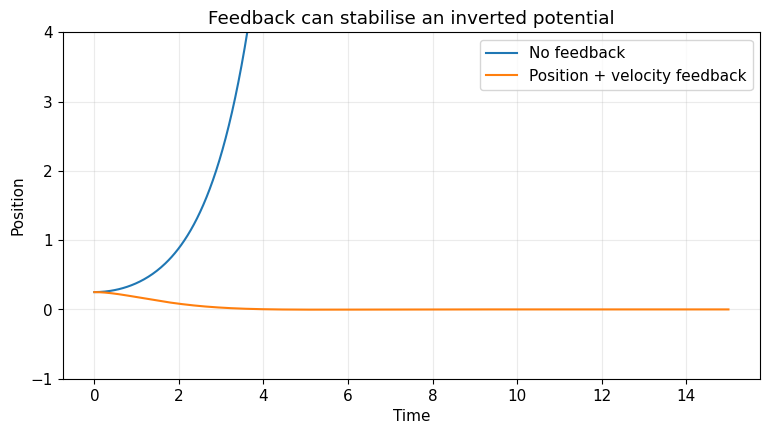

Open-loop poles: [ 0.942 -1.062]
Closed-loop poles: [-0.81+0.586j -0.81-0.586j]


In [6]:
from scipy.integrate import solve_ivp
K_example=np.array([2.0,1.5])
Aunstable=plant(-1)
Acl=Aunstable-B@K_example[None,:]
sol0=solve_ivp(lambda t,z:Aunstable@z,[0,15],z0,t_eval=np.linspace(0,15,600))
sol1=solve_ivp(lambda t,z:Acl@z,[0,15],z0,t_eval=np.linspace(0,15,600))
plt.plot(sol0.t,sol0.y[0],label='No feedback')
plt.plot(sol1.t,sol1.y[0],label='Position + velocity feedback')
plt.ylim(-1,4);plt.xlabel('Time');plt.ylabel('Position');plt.title('Feedback can stabilise an inverted potential');plt.legend();plt.show()
print('Open-loop poles:',np.linalg.eigvals(Aunstable).round(3))
print('Closed-loop poles:',np.linalg.eigvals(Acl).round(3))

## 6. From feedback to optimal control: LQR

Rather than guessing \(k_x\) and \(k_v\), choose them to minimise

\[
J=\int_0^\infty(z^TQ_cz+ru^2)\,dt,\quad z=[x,v]^T.
\]

The matrix \(Q_c\) penalises displacement and velocity; \(r>0\) penalises control effort. For a *stable* harmonic trap, a physical energy-motivated choice is \(Q_c\propto\operatorname{diag}(\Omega_0^2,1)\). For the *inverted* trap, this is a positive surrogate state penalty, **not** the physical potential energy (which has negative curvature).

The optimal gain is \(K=r^{-1}B^TP\), where \(P\) solves the continuous algebraic Riccati equation

\[
A^TP+PA-PBr^{-1}B^TP+Q_c=0.
\]

The paper implements a **discrete-time** LQR on the FPGA; here we first use continuous-time LQR to make the intuition clear.

In [7]:
Qcontrol=np.diag([2.,1.]);rcontrol=np.array([[.5]])
def lqr(A,Q=Qcontrol,R=rcontrol):
    P=solve_continuous_are(A,B,Q,R)
    return np.linalg.solve(R,B.T@P)
for s in [1,-1]:
    K=lqr(plant(s))
    print(('Stable' if s==1 else 'Inverted'), 'LQR gain [kx, kv] =',np.round(K.ravel(),3),
          'closed-loop poles =',np.round(np.linalg.eigvals(plant(s)-B@K),3))

Stable LQR gain [kx, kv] = [1.236 1.998] closed-loop poles = [-1.059+1.056j -1.059-1.056j]
Inverted LQR gain [kx, kv] = [3.236 2.793] closed-loop poles = [-1.457+0.338j -1.457-0.338j]


## 7. Why do we need a Kalman filter?

A photodetector provides a noisy signal related to **position**. It generally does not measure velocity directly. Differentiating noisy position samples makes the noise much worse.

A Kalman filter combines a dynamical model with incoming measurements to estimate both position and velocity:

\[
z_{k+1}=A_dz_k+B_du_k+w_k,\qquad y_k=Cz_k+v_k,\quad C=[1\;0].
\]

Here \(w_k\) and \(v_k\) are independent zero-mean Gaussian process and measurement noise with covariances \(Q_d\) and \(R_d\). The Kalman filter alternates **prediction** and **measurement correction**. We use an exact zero-order-hold discretisation for the deterministic model and the exact integrated covariance for continuous white acceleration noise.

In [8]:
dt=.04
A=plant(-1)
Ad,Bd,_,_,_=cont2discrete((A,B,np.array([[1.,0.]]),np.array([[0.]])),dt)
C=np.array([[1.,0.]])
# Exact covariance for white acceleration forcing with spectral density qacc
qacc=.12
Qc=qacc*(B@B.T)
M=np.block([[A,Qc],[np.zeros((2,2)),-A.T]])*dt
E=expm(M)
Qd=E[:2,2:]@E[:2,:2].T
Qd=(Qd+Qd.T)/2
Rmeas=.04**2
print('Discrete A:',Ad.round(4),' | Discrete process covariance:',Qd.round(7))

Discrete A: [[1.0008 0.0399]
 [0.0399 0.996 ]]  | Discrete process covariance: [[2.6000e-06 9.5600e-05]
 [9.5600e-05 4.7796e-03]]


### A single, reproducible stochastic experiment

To keep comparisons fair, the open-loop, full-state LQR, and LQG controllers experience the **same sequence of random force disturbances**. The measurement noise is also fixed in advance. The unstable open-loop trajectory will rapidly escape; in a real double well, nonlinear forces would eventually matter, so do not interpret the linear open-loop trajectory at very large displacements as physically realistic.

The filter uses the standard *predict → correct* recursion, with covariance updates in Joseph form for numerical robustness. Control is applied after the current measurement has been processed.

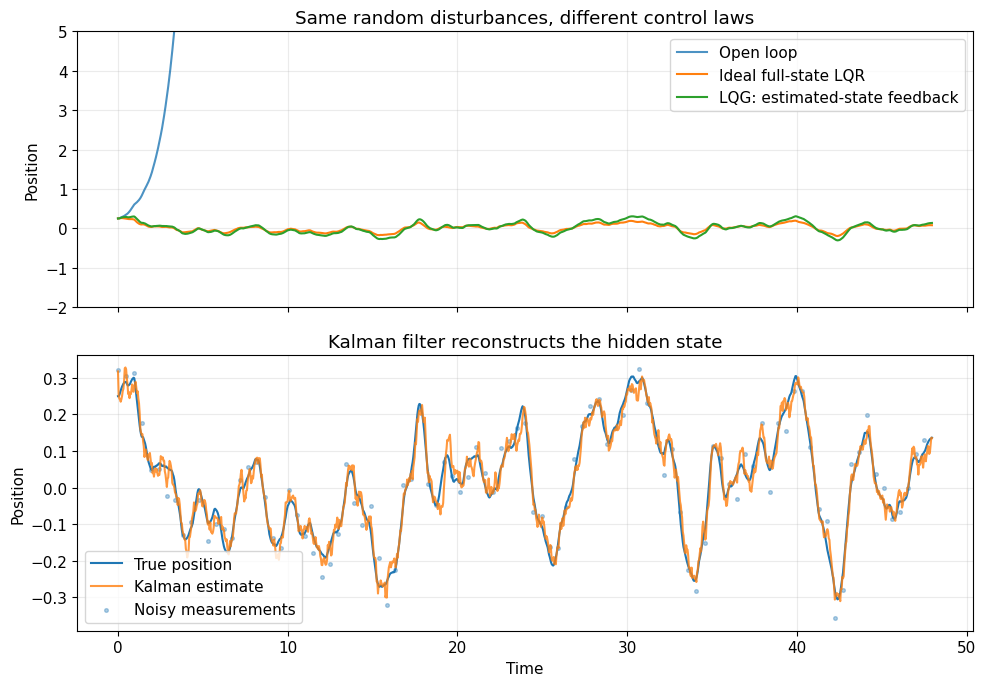

In [9]:
N=1200
rng=np.random.default_rng(2026)
W=rng.multivariate_normal([0,0],Qd,size=N)
V=rng.normal(0,np.sqrt(Rmeas),size=N)
K=lqr(A)
def simulate(mode):
    z=np.array([.25,0.]);zh=np.zeros(2);P=np.eye(2)*.2
    states=[];est=[];us=[];measure=[]
    for k in range(N):
        y=(C@z)[0]+V[k]
        # Measurement update
        innovation=y-(C@zh)[0]
        S=(C@P@C.T)[0,0]+Rmeas
        L=(P@C.T/S).ravel()
        zh=zh+L*innovation
        T=np.eye(2)-np.outer(L,C.ravel())
        P=T@P@T.T+np.outer(L,L)*Rmeas
        u=0. if mode=='open' else float(-(K@(z if mode=='full' else zh))[0])
        states.append(z.copy());est.append(zh.copy());us.append(u);measure.append(y)
        z=Ad@z+Bd.ravel()*u+W[k]
        zh=Ad@zh+Bd.ravel()*u
        P=Ad@P@Ad.T+Qd
    return np.array(states),np.array(est),np.array(us),np.array(measure)
open_state,_,_,_=simulate('open')
full_state,_,full_u,_=simulate('full')
lqg_state,lqg_est,lqg_u,lqg_y=simulate('lqg')
time=np.arange(N)*dt
fig,axs=plt.subplots(2,1,figsize=(10,7),sharex=True)
axs[0].plot(time,open_state[:,0],label='Open loop',alpha=.8)
axs[0].plot(time,full_state[:,0],label='Ideal full-state LQR')
axs[0].plot(time,lqg_state[:,0],label='LQG: estimated-state feedback')
axs[0].set(ylim=(-2,5),ylabel='Position',title='Same random disturbances, different control laws');axs[0].legend()
axs[1].plot(time,lqg_state[:,0],label='True position')
axs[1].plot(time,lqg_est[:,0],label='Kalman estimate',alpha=.8)
axs[1].scatter(time[::12],lqg_y[::12],s=7,alpha=.35,label='Noisy measurements')
axs[1].set(xlabel='Time',ylabel='Position',title='Kalman filter reconstructs the hidden state');axs[1].legend()
fig.tight_layout();plt.show()

## 8. LQG = LQR + Kalman filter

The **separation principle** says that, under the standard linear-Gaussian assumptions, the estimator and optimal feedback gains can be designed separately:

\[
\boxed{u_k=-K_d\hat z_{k|k}}.
\]

Our simulation above uses a continuous-time LQR gain applied to a sampled plant (adequate here at small \(dt\)). For the paper's FPGA, a **discrete-time LQR gain** is calculated directly. The following cell computes that exact discrete-time gain and compares it with our approximation.

In [10]:
Pd=solve_discrete_are(Ad,Bd,Qcontrol*dt,rcontrol*dt)
Kd=np.linalg.solve(Bd.T@Pd@Bd+rcontrol*dt,Bd.T@Pd@Ad)
print('Continuous-time LQR gain:',K.round(4))
print('Discrete-time LQR gain:  ',Kd.round(4))
print('Discrete closed-loop eigenvalues:',np.linalg.eigvals(Ad-Bd@Kd).round(4))

Continuous-time LQR gain: [[3.2361 2.7932]]
Discrete-time LQR gain:   [[3.1146 2.6977]]
Discrete closed-loop eigenvalues: [0.9433+0.0128j 0.9433-0.0128j]


## 9. Cooling and stabilisation are different control objectives

**Stable trap:** feedback can increase damping and reduce stationary motion in the presence of random forces. **Inverted trap:** without feedback, there is no stationary distribution about the central equilibrium; the first priority is to make the closed-loop dynamics stable.

For a stable linear system with white process noise, the steady-state state covariance \(\Sigma\) satisfies the discrete Lyapunov equation

\[
\Sigma=A_{\rm cl}\Sigma A_{\rm cl}^T+Q_d.
\]

The mechanical energy in a *stable* harmonic trap (with \(m=1\)) is \(E=(v^2+\Omega^2x^2)/2\). A smaller stationary variance corresponds to less mechanical energy. Here we simulate both open-loop and full-state velocity-feedback cooling; measurement-based LQG can add noise through its imperfect estimates.

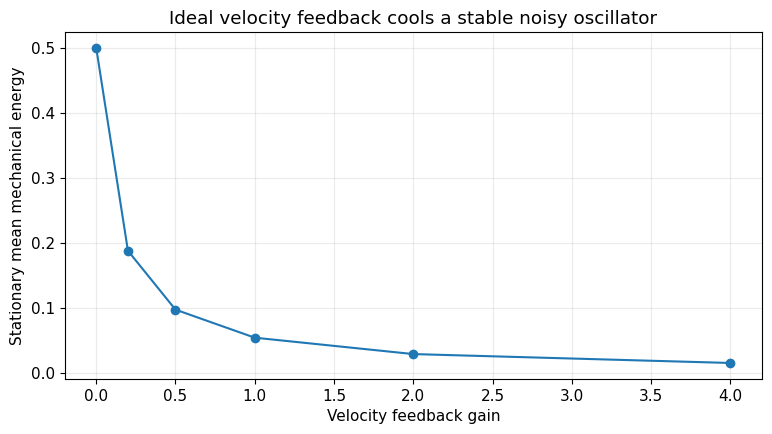

Energy without feedback: 0.5   with gain 2: 0.0289


In [11]:
from scipy.linalg import solve_discrete_lyapunov
Ast=plant(1)
Ads,Bds,_,_,_=cont2discrete((Ast,B,C,np.zeros((1,1))),dt)
M=np.block([[Ast,Qc],[np.zeros((2,2)),-Ast.T]])*dt
EM=expm(M);Qds=EM[:2,2:]@EM[:2,:2].T;Qds=(Qds+Qds.T)/2
energy=[]
for kv in [0,.2,.5,1.,2.,4.]:
    F=Ads-Bds@np.array([[0.,kv]])
    Sigma=solve_discrete_lyapunov(F,Qds)
    energy.append(.5*(Sigma[0,0]+Sigma[1,1]))
plt.plot([0,.2,.5,1.,2.,4.],energy,'o-');plt.xlabel('Velocity feedback gain');plt.ylabel('Stationary mean mechanical energy')
plt.title('Ideal velocity feedback cools a stable noisy oscillator');plt.show()
print('Energy without feedback:',round(energy[0],4),'  with gain 2:',round(energy[-2],4))

**Caveat:** The preceding graph assumes ideal full-state feedback, no actuator limits and no measurement noise. A practical LQG controller has an optimum gain; stronger feedback is not always better once measurement noise, bandwidth, delay, and quantisation are included.

## 10. The paper's double-well / saddle example

The paper's illustrative two-dimensional potential is **separable**:

\[
V_{\rm con}(x,y)=\tfrac12\Omega_x^2x^2+\tfrac12\Omega_y^2y^2,
\]
\[
V_{\rm sad}(x,y)=\tfrac14\alpha_x^4x^4-\tfrac12\Omega_x^2x^2+\tfrac12\Omega_y^2y^2.
\]

At the origin, the saddle is unstable in \(x\), stable in \(y\). Away from the origin, the quartic term produces two wells in \(x\). The paper uses a **linear** LQG controller around the target operating point, while its hardware-in-the-loop simulator models the **nonlinear** potential. This difference is important: local feedback stability does not imply global performance throughout the double well.

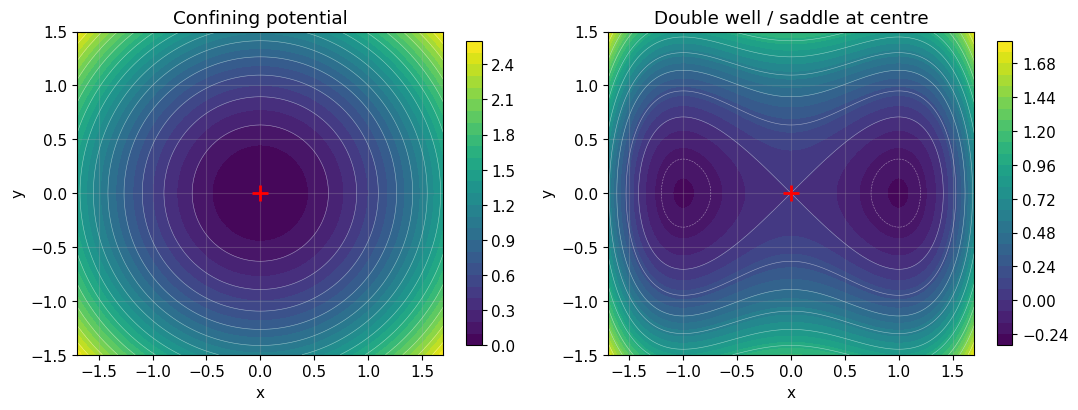

In [12]:
xx=np.linspace(-1.7,1.7,180);yy=np.linspace(-1.5,1.5,160)
X,Y=np.meshgrid(xx,yy)
Vcon=.5*(X**2+Y**2)
Vsad=.25*X**4-.5*X**2+.5*Y**2
fig,axs=plt.subplots(1,2,figsize=(11,4.3))
for a,Z,title in zip(axs,[Vcon,Vsad],['Confining potential','Double well / saddle at centre']):
    cs=a.contourf(X,Y,Z,levels=30,cmap='viridis');a.contour(X,Y,Z,levels=12,colors='white',linewidths=.4,alpha=.5)
    a.plot(0,0,'r+',ms=11,mew=2);a.set(xlabel='x',ylabel='y',title=title,aspect='equal');fig.colorbar(cs,ax=a,shrink=.8)
fig.tight_layout();plt.show()

### Nonlinear particle with and without stabilising feedback

Use the dimensionless saddle potential \(V(x)=x^4/4-x^2/2\), so the force is \(F(x)=x-x^3\). With no feedback, a particle near \(x=0\) rolls toward one of the wells. With LQR feedback designed from the **linearisation** \(\ddot x\approx x-\Gamma\dot x+u\), it can remain close to \(x=0\).

This is a simplified analogue of the paper's Fig. 5, **not** a numerical reproduction of that figure.

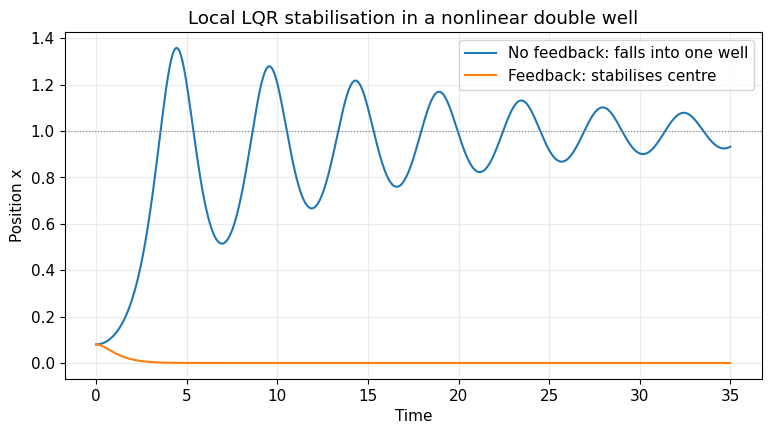

In [13]:
def nonlinear_saddle(t,z,feedback):
    x,v=z
    u=float(-(K@z)[0]) if feedback else 0.
    return [v,x-x**3-gamma*v+u]
tp=np.linspace(0,35,1200)
free=solve_ivp(lambda t,z:nonlinear_saddle(t,z,False),[0,35],[.08,0],t_eval=tp,rtol=1e-9,atol=1e-11)
controlled=solve_ivp(lambda t,z:nonlinear_saddle(t,z,True),[0,35],[.08,0],t_eval=tp,rtol=1e-9,atol=1e-11)
plt.plot(tp,free.y[0],label='No feedback: falls into one well')
plt.plot(tp,controlled.y[0],label='Feedback: stabilises centre')
plt.axhline(1,color='gray',ls=':',lw=.8);plt.xlabel('Time');plt.ylabel('Position x');plt.title('Local LQR stabilisation in a nonlinear double well');plt.legend();plt.show()

## 11. What does the FPGA add?

The **control theory** is standard; the engineering challenge is to run it deterministically with low latency and controlled numerical error.

In the supplied paper:

- The FPGA controller uses a **64 ns sample period** (15.625 MHz) and fixed-point matrix operations.
- It supports **up to three oscillatory degrees of freedom plus a drift state**, with two analogue inputs and two outputs.
- The authors describe state-space rescaling to reduce fixed-point quantisation problems.
- A second Red Pitaya FPGA implements a stochastic nonlinear **hardware-in-the-loop (HIL) plant**, including lookup-table nonlinearities and noise generators.
- Their end-to-end example demonstrates a transition from a confining potential to a saddle potential and back, including loss of confinement when feedback is disabled.

The demonstration is **HIL, not a new measurement of quantum ground-state cooling**. In the real experiment, the simulated plant would be replaced by an optically trapped particle and the voltages would drive a physical actuator.

### Why latency matters

If feedback is delayed, a force intended to oppose velocity may arrive at the wrong phase of the oscillation. The next figure shows the phase lag \(\varphi=\Omega\tau\) for several delays, as a simple first-order illustration. A full stability assessment must include the sampled controller and actuator dynamics.

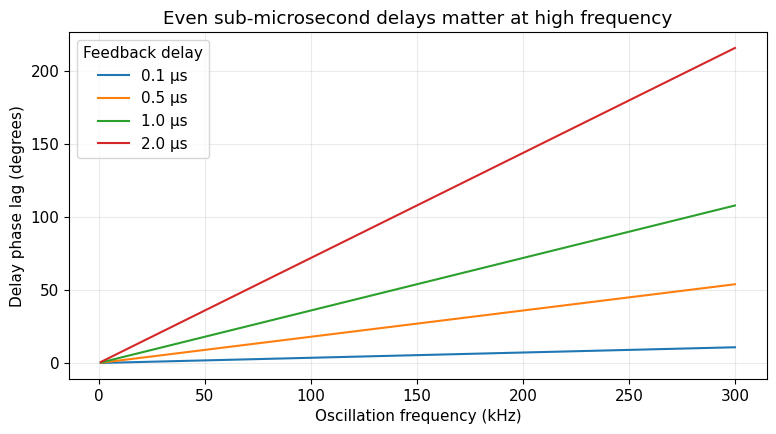

In [14]:
freq=np.linspace(1e3,300e3,400)
for delay_us in [.1,.5,1.,2.]:
    plt.plot(freq/1e3,360*freq*delay_us*1e-6,label=f'{delay_us} µs')
plt.xlabel('Oscillation frequency (kHz)');plt.ylabel('Delay phase lag (degrees)');plt.title('Even sub-microsecond delays matter at high frequency');plt.legend(title='Feedback delay');plt.show()

## 12. Putting it all together

1. **Optical field:** a focused beam creates a spatially varying optical potential.
2. **Mechanical plant:** the particle follows a noisy second-order equation of motion.
3. **Stable trap:** optical restoring forces already confine the particle; feedback can cool its motion.
4. **Saddle trap:** the desired equilibrium is unstable without feedback; active position feedback must first supply effective positive stiffness.
5. **Kalman filter:** estimates position and velocity from noisy detector outputs.
6. **LQR:** chooses feedback gains that trade state excursions against actuation effort.
7. **LQG:** combines those two components; the FPGA makes the loop fast and deterministic.
8. **HIL:** replaces the physical particle with a nonlinear stochastic real-time simulator to test the controller safely.

### Exercises (change code and rerun)

- Increase `Rmeas` tenfold in §7. Does the Kalman estimate become less reliable? How does the LQG trajectory change?
- Increase `rcontrol` in §6. Why does the controller become less aggressive?
- Change `gamma` in §4 and re-run the simulation. What happens to the open-loop unstable pole?
- In §10–11, try a larger initial displacement in the nonlinear saddle. When does the linear feedback cease to behave as expected?
- Replace the continuous-time LQR gain in §7 with the discrete-time `Kd` computed in §8. Compare the results.

### Further reading

- Mlynář et al. (2026), *FPGA-based LQG controller and hardware-in-the-loop simulator implementation for nanomechanical systems*, supplied PDF, especially §§2 and 4.
- Winstone et al. (2023), *Optomechanics of optically-levitated particles: A tutorial and perspective*, arXiv:2307.11858.
- Millen et al. (2020), *Optomechanics with levitated particles*, *Reports on Progress in Physics* 83, 026401.

**Limitations of this notebook:** classical linear-Gaussian noise; simplified 1D dynamics for control; illustrative normalised values; no photon-recoil quantum backaction, actuator saturation, explicit fixed-point FPGA model, or detailed optical scattering calculation. These would be natural follow-on topics.